# 03 Analyse: cost benchmark
Which towns cost more than they should, given who lives there? Which care types cause it? Does poor health explain it?

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Load the clean Vektis table
vektis = pd.read_csv("../data/processed/vektis_clean.csv")

In [3]:
# Check Vektis shape
vektis.shape

(12991, 45)

In [4]:
# One row per age(19 age bands) and sex(2, m,v ) group = 38 groups(2*19), total cost and insured-year
# Right now I have 12,991 rows (one per town × sex × age). I want 38

# National totals per sex and age group: sum cost and insured-years over all towns
rates = vektis.groupby(["geslacht", "age_from"])[["cost_total", "aantal_verzekerdejaren"]].sum()

rates.shape

(38, 2)

In [5]:
# rate = the national average cost per person (per insured-year) for one sex and age group. 
# Reference rate: national average cost per insured-year, per sex and age group
rates["rate"] = rates["cost_total"] / rates["aantal_verzekerdejaren"]

In [9]:
# Move sex and age out of the index into normal columns, so they can be filtered and plotted
rates_flat = rates.reset_index()

rates_flat.shape

(38, 5)

In [ ]:
# One table per sex, so each gets its own line in the chart
men = rates_flat[rates_flat["geslacht"] == "M"]
women = rates_flat[rates_flat["geslacht"] == "V"]
len(men), len(women)

(19, 19)

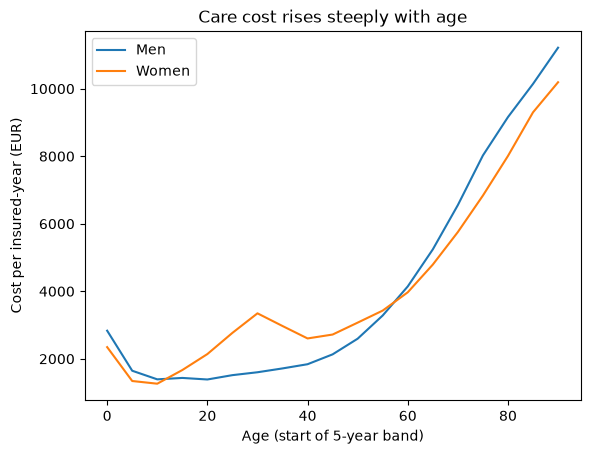

In [16]:
# Sanity chart: national cost per insured-year by age, one line per sex
import matplotlib.pyplot as plt

plt.plot(men["age_from"], men["rate"], label="Men")
plt.plot(women["age_from"], women["rate"], label="Women")
plt.xlabel("Age (start of 5-year band)")
plt.ylabel("Cost per insured-year (EUR)")
plt.title("Care cost rises steeply with age")
plt.legend()
plt.show()
